# Entropy Calculation

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Prepare Inputs

In [22]:
distros = dist.DISTRIBUTIONS[:3]       
n =np.array([0.01] + [0.025 + 0.025 * x for x in range(39)] + [0.99])
betas= list(np.logspace(-2,3,61))
betas.append(0.2)
betas.append(np.inf)
betas = np.sort(betas)
betas = np.round(betas, 4)

In [23]:
betas_to_plot =  [1000, 100, 10]
n_to_plot = np.array([0.5, 0.9, 0.99])

## 2D Lattice

In [24]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, KX, KY = dist.prepare_2D_lattice_data(kx, ky, t, t_prim)

## Prepare data structures

In [25]:
n = np.round(n, 3)
multi_index = pd.MultiIndex.from_product([distros, betas], names=["distributions", "beta"])

try:
    mu = pd.read_csv("temp//chemical_potential_2d_lattice.csv")
    mu.index = multi_index
except FileNotFoundError:
    mu = pd.DataFrame(columns=n, index=multi_index)
    for beta in betas:
        for distro in distros:
            print(f"\n Calculating chemical_potential for {distro} with beta={beta} \n")
            for n_val in n:
                mu.loc[(distro, beta), n_val] = cp.chemical_potential_computation(distro=distro, n=n_val, beta=beta, e_k=e_k, kx=kx, ky=ky)
    
    mu.to_csv("temp/chemical_potential_2d_lattice.csv")    

entropy = pd.DataFrame(columns=n, index=multi_index)
energy = pd.DataFrame(columns=n, index=multi_index)
freedom_energy = pd.DataFrame(columns=n, index=multi_index)

# Entropy

In [26]:
if not os.path.exists("temp/entropy_2d_lattice.csv"):
    for beta in betas:
        for distro in distros:
            mu_distro = mu.loc[(distro, beta), :]
            mu_distro = mu_distro.to_numpy()[2:]  # Except headers
            # print(f"\n Calculating entropy for {distro} with beta={beta} \n")
            entropy.loc[(distro, beta), :] = ent.calculate_entropy(distro=distro, n=n, beta=beta, e_k=e_k, kx=kx, ky=ky, mu=mu_distro)
    
    entropy.to_csv("temp/entropy_2d_lattice.csv")    
    
else:    
    entropy = pd.read_csv("temp/entropy_2d_lattice.csv", index_col=[0, 1])
    entropy.index = multi_index

In [27]:
entropy.T

distributions        FD                                                    \
beta          0.0100    0.0121    0.0147    0.0178    0.0215    0.0261      
0.01           0.062956  0.062956  0.062954  0.062952  0.062949  0.062945   
0.025          0.134389  0.134387  0.134383  0.134378  0.134371  0.134360   
0.05           0.233805  0.233800  0.233793  0.233783  0.233768  0.233747   
0.075          0.319818  0.319811  0.319802  0.319786  0.319764  0.319732   
0.1            0.397013  0.397003  0.396991  0.396969  0.396941  0.396898   
0.125          0.467560  0.467549  0.467532  0.467508  0.467473  0.467420   
0.15           0.532741  0.532728  0.532708  0.532677  0.532638  0.532575   
0.175          0.593400  0.593382  0.593359  0.593327  0.593280  0.593208   
0.2            0.650130  0.650113  0.650087  0.650049  0.649997  0.649915   
0.225          0.703380  0.703361  0.703334  0.703291  0.703231  0.703142   
0.25           0.753497  0.753476  0.753443  0.753398  0.753333  0.753234   
0.275          0.800750  0.800727  0.800693  0.800644  0.800573  0.800466   
0.3            0.845366  0.845342  0.845305  0.845252  0.845175  0.845060   
0.325          0.887529  0.887502  0.887463  0.887407  0.887325  0.887203   
0.35           0.927395  0.927366  0.927324  0.927264  0.927177  0.927046   
0.375          0.965093  0.965064  0.965018  0.964956  0.964864  0.964726   
0.4            1.000740  1.000707  1.000662  1.000595  1.000498  1.000353   
0.425          1.034431  1.034399  1.034351  1.034280  1.034179  1.034028   
0.45           1.066256  1.066222  1.066171  1.066098  1.065993  1.065835   
0.475          1.096288  1.096251  1.096199  1.096124  1.096014  1.095849   
0.5            1.124593  1.124556  1.124502  1.124424  1.124309  1.124139   
0.525          1.151231  1.151193  1.151137  1.151056  1.150938  1.150762   
0.55           1.176255  1.176217  1.176158  1.176074  1.175953  1.175771   
0.575          1.199711  1.199671  1.199612  1.199525  1.199401  1.199214   
0.6            1.221641  1.221600  1.221539  1.221450  1.221323  1.221131   
0.625          1.242083  1.242042  1.241979  1.241888  1.241757  1.241561   
0.65           1.261070  1.261028  1.260964  1.260870  1.260737  1.260536   
0.675          1.278633  1.278589  1.278524  1.278429  1.278293  1.278088   
0.7            1.294798  1.294754  1.294687  1.294591  1.294452  1.294243   
0.725          1.309589  1.309544  1.309476  1.309378  1.309237  1.309025   
0.75           1.323028  1.322982  1.322913  1.322814  1.322671  1.322455   
0.775          1.335134  1.335087  1.335017  1.334917  1.334771  1.334553   
0.8            1.345922  1.345875  1.345805  1.345703  1.345556  1.345335   
0.825          1.355409  1.355361  1.355290  1.355187  1.355039  1.354815   
0.85           1.363606  1.363558  1.363486  1.363382  1.363232  1.363007   
0.875          1.370524  1.370476  1.370404  1.370299  1.370148  1.369920   
0.9            1.376173  1.376124  1.376051  1.375946  1.375794  1.375565   
0.925          1.380559  1.380510  1.380437  1.380330  1.380177  1.379947   
0.95           1.383688  1.383639  1.383565  1.383458  1.383305  1.383074   
0.975          1.385563  1.385514  1.385440  1.385333  1.385179  1.384947   
0.99           1.386088  1.386039  1.385965  1.385858  1.385704  1.385472   

distributions                                          ...       NFL  \
beta          0.0316    0.0383    0.0464    0.0562     ... 215.4435    
0.01           0.062938  0.062930  0.062916  0.062896  ...  0.011819   
0.025          0.134344  0.134321  0.134288  0.134239  ...  0.021856   
0.05           0.233714  0.233670  0.233603  0.233508  ...  0.039072   
0.075          0.319685  0.319618  0.319520  0.319377  ...  0.056769   
0.1            0.396840  0.396748  0.396619  0.396430  ...  0.074741   
0.125          0.467345  0.467234  0.467074  0.466842  ...  0.091397   
0.15           0.532486  0.532355  0.532165  0.531889  ...  0.110739   
0.175          0.593103  0.592953  0.592

#### $\frac{S} {k_B N} = f(n)$

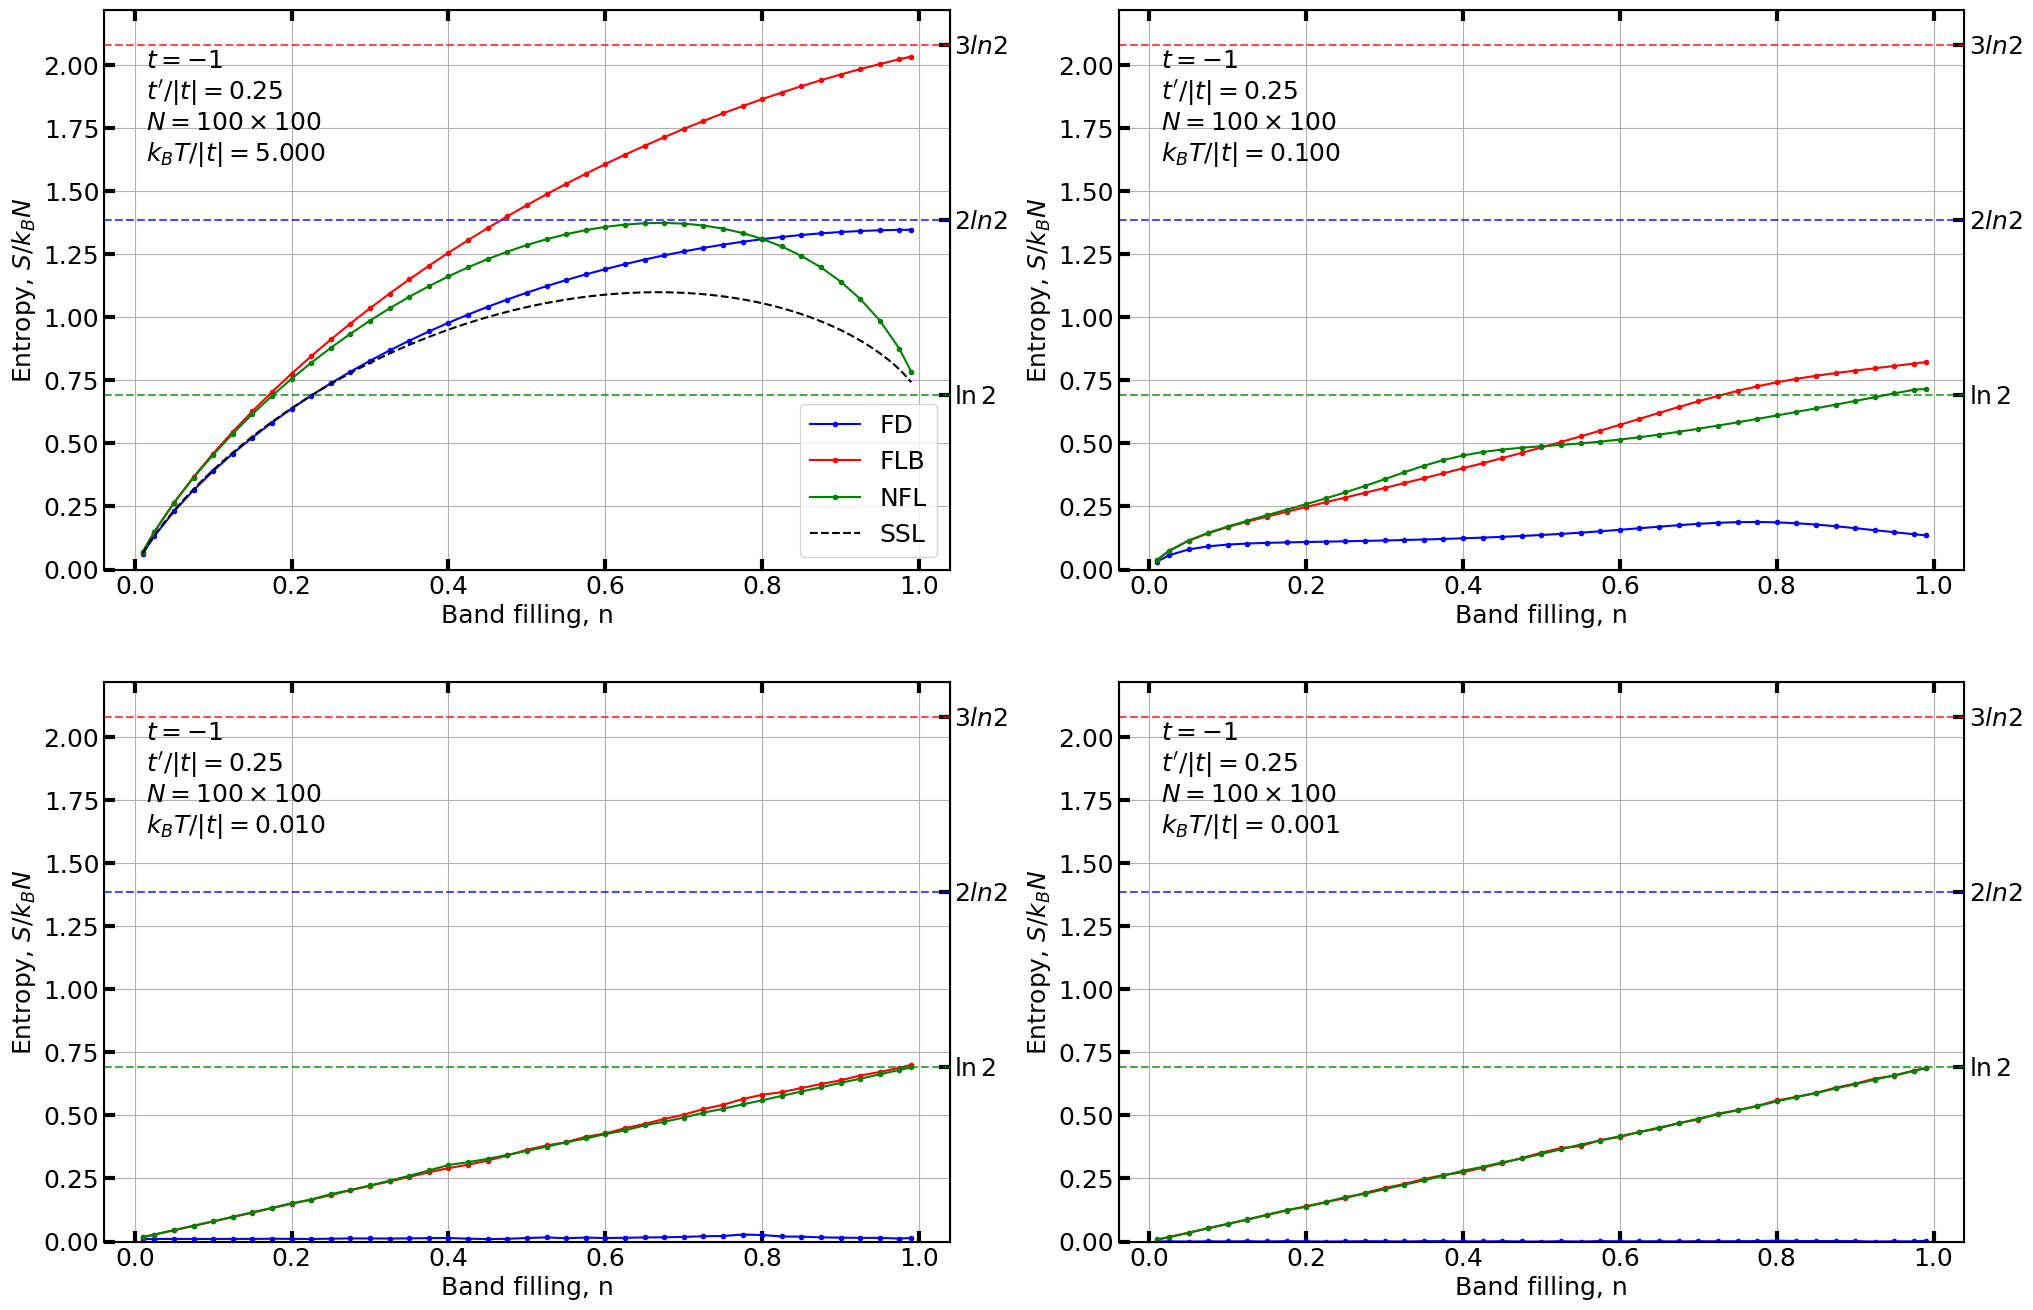

In [28]:
sf.plot_result_n(results=entropy, n=n, betas=[0.2, 10, 100, 1000], distros=distros, fontsize =18, figsize=(12,8), t_prim=t_prim,
                y_label="Entropy, $S / k_B N$", cols=2, show_log_vals=True, only_one_legend=True, text_pos=(0.05, 0.93),
                legend_position="lower right", ssl_theory=[0])

plt.savefig("temp/S_n.png", dpi=600, bbox_inches='tight')

#### $\frac{S} {k_B N} = f(k_BT)$

<Figure size 640x480 with 0 Axes>

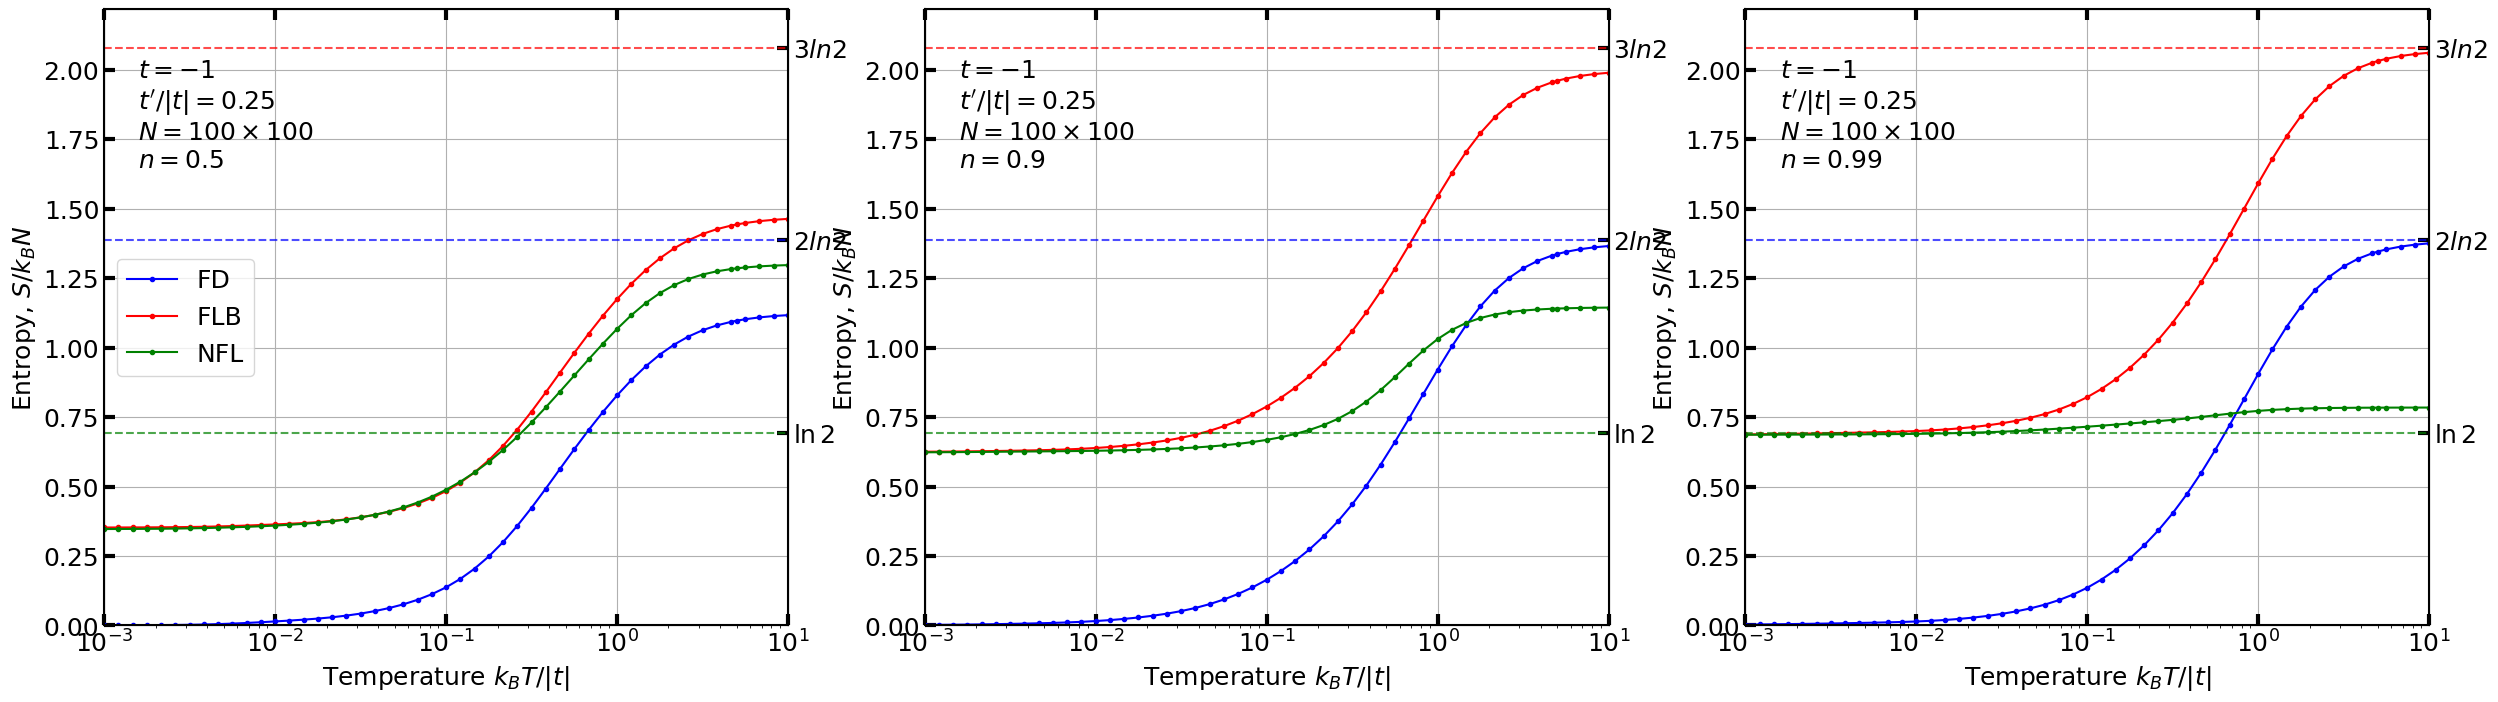

In [29]:
sf.plot_results_temperature(results=entropy, n=n_to_plot, betas=betas, distros=distros, cols = 3,t_prim=t_prim,
                        y_label="Entropy, $S / k_B N$", show_log_vals=True, only_one_legend=True, xlims = (1e-3,10),
                        legend_position="center left", text_pos=(0.05, 0.92), fontsize =18, figsize=(10, 8))

plt.savefig("temp/S_kBT.png", dpi=600, bbox_inches='tight')

# Energia stanu podstawowego

Energia stanu podstawowego $ n \in [0,1]$, dla dwóch temperatur $\frac{k_BT}{ |t|} \in \{10^{-3}, 1\}$:
$$ \frac{E}{N|t|} = \frac{1}{N|t|} \sum_k \epsilon_k n_k

In [30]:
if not os.path.exists("temp/energy_2d_lattice.csv"):
    for beta in betas:
        for distro in distros:
            mu_distro = mu.loc[(distro, beta), :]
            mu_distro = mu_distro.to_numpy()[2:] # Except headers
            # print(f"\n Calculating energy for {distro} with beta={beta} \n")
            energy.loc[(distro, beta), :] = eng.energy(distro=distro, beta=beta, n=n, e_k=e_k, kx=kx, ky=ky, mu=mu_distro)
    
    energy.to_csv("temp/energy_2d_lattice.csv")    
    
else:    
    energy = pd.read_csv("temp/energy_2d_lattice.csv", index_col=[0, 1])
    energy.index = multi_index

In [31]:
energy.T

distributions        FD                                                    \
beta          0.0100    0.0121    0.0147    0.0178    0.0215    0.0261      
0.01          -0.000424 -0.000511 -0.000619 -0.000747 -0.000899 -0.001087   
0.025         -0.001052 -0.001269 -0.001536 -0.001854 -0.002232 -0.002698   
0.05          -0.002077 -0.002506 -0.003035 -0.003663 -0.004409 -0.005331   
0.075         -0.003077 -0.003712 -0.004495 -0.005426 -0.006531 -0.007897   
0.1           -0.004051 -0.004887 -0.005918 -0.007143 -0.008599 -0.010398   
0.125         -0.004998 -0.006030 -0.007303 -0.008815 -0.010611 -0.012833   
0.15          -0.005920 -0.007142 -0.008649 -0.010441 -0.012569 -0.015202   
0.175         -0.006816 -0.008222 -0.009958 -0.012021 -0.014473 -0.017505   
0.2           -0.007685 -0.009271 -0.011229 -0.013555 -0.016321 -0.019741   
0.225         -0.008528 -0.010288 -0.012461 -0.015044 -0.018114 -0.021912   
0.25          -0.009345 -0.011274 -0.013656 -0.016486 -0.019852 -0.024016   
0.275         -0.010136 -0.012228 -0.014812 -0.017883 -0.021534 -0.026053   
0.3           -0.010901 -0.013151 -0.015930 -0.019234 -0.023162 -0.028024   
0.325         -0.011640 -0.014042 -0.017010 -0.020538 -0.024734 -0.029928   
0.35          -0.012352 -0.014902 -0.018052 -0.021797 -0.026251 -0.031766   
0.375         -0.013039 -0.015730 -0.019055 -0.023009 -0.027713 -0.033537   
0.4           -0.013699 -0.016527 -0.020021 -0.024176 -0.029119 -0.035240   
0.425         -0.014333 -0.017292 -0.020948 -0.025296 -0.030469 -0.036877   
0.45          -0.014940 -0.018025 -0.021836 -0.026369 -0.031764 -0.038447   
0.475         -0.015522 -0.018726 -0.022686 -0.027397 -0.033004 -0.039950   
0.5           -0.016077 -0.019396 -0.023498 -0.028378 -0.034187 -0.041385   
0.525         -0.016606 -0.020034 -0.024272 -0.029313 -0.035315 -0.042753   
0.55          -0.017108 -0.020641 -0.025006 -0.030202 -0.036387 -0.044053   
0.575         -0.017585 -0.021215 -0.025703 -0.031044 -0.037403 -0.045286   
0.6           -0.018035 -0.021758 -0.026361 -0.031839 -0.038363 -0.046451   
0.625         -0.018458 -0.022269 -0.026980 -0.032588 -0.039267 -0.047549   
0.65          -0.018856 -0.022748 -0.027561 -0.033290 -0.040115 -0.048578   
0.675         -0.019226 -0.023195 -0.028103 -0.033946 -0.040907 -0.049540   
0.7           -0.019571 -0.023611 -0.028607 -0.034555 -0.041642 -0.050434   
0.725         -0.019889 -0.023994 -0.029072 -0.035117 -0.042321 -0.051259   
0.75          -0.020181 -0.024346 -0.029498 -0.035633 -0.042944 -0.052016   
0.775         -0.020446 -0.024666 -0.029885 -0.036102 -0.043511 -0.052706   
0.8           -0.020685 -0.024954 -0.030234 -0.036524 -0.044021 -0.053326   
0.825         -0.020898 -0.025210 -0.030544 -0.036899 -0.044474 -0.053878   
0.85          -0.021084 -0.025433 -0.030815 -0.037227 -0.044871 -0.054362   
0.875         -0.021243 -0.025625 -0.031048 -0.037508 -0.045211 -0.054777   
0.9           -0.021377 -0.025785 -0.031241 -0.037742 -0.045495 -0.055123   
0.925         -0.021483 -0.025913 -0.031395 -0.037929 -0.045721 -0.055400   
0.95          -0.021563 -0.026009 -0.031511 -0.038069 -0.045891 -0.055609   
0.975         -0.021617 -0.026072 -0.031588 -0.038161 -0.046004 -0.055748   
0.99          -0.021636 -0.026095 -0.031615 -0.038194 -0.046044 -0.055798   

distributions                                          ...       NFL  \
beta          0.0316    0.0383    0.0464    0.0562     ... 215.4435    
0.01          -0.001310 -0.001579 -0.001901 -0.002285  ... -0.029805   
0.025         -0.003252 -0.003920 -0.004719 -0.005672  ... -0.072830   
0.05          -0.006425 -0.007746 -0.009325 -0.011210  ... -0.142184   
0.075         -0.009519 -0.011478 -0.013820 -0.016616  ... -0.207565   
0.1           -0.012535 -0.015115 -0.018202 -0.021888  ... -0.269998   
0.125         -0.015471 -0.018658 -0.022472 -0.027027  ... -0.324980   
0.15          -0.018329 -0.022107 -0.026628 -0.032031  ... -0.382728   
0.175         -0.021107 -0.025460 -0.030

#### $\frac{E} {k_B N} = f(n)$

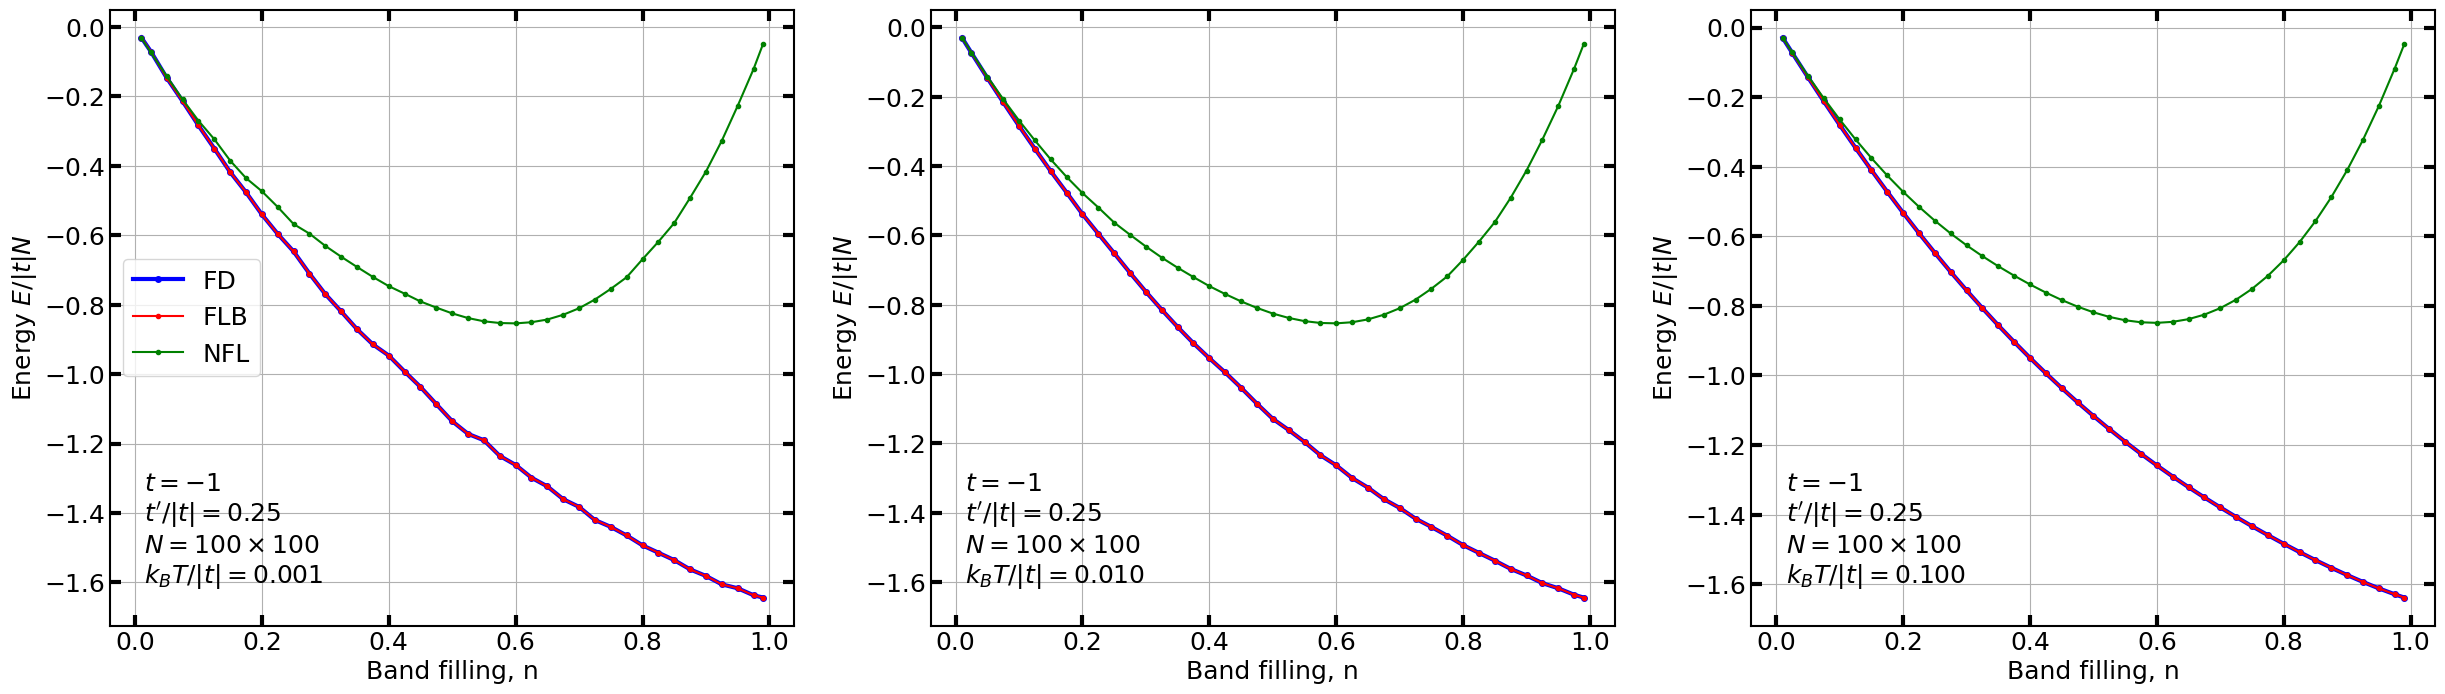

In [32]:
sf.plot_result_n(results=energy, n=n, betas=betas_to_plot, distros=distros, t_prim=t_prim,
                y_label="Energy $E / |t| N$", cols=3, legend_position="center left", text_pos=(0.05, 0.25),
                fontsize =18, figsize=(10, 8), only_one_legend=True, blue_line=True)

plt.savefig("temp/E_n.png", dpi=600, bbox_inches='tight')

#### $\frac{E} {k_B N} = f(k_B T / |t|)$

<Figure size 640x480 with 0 Axes>

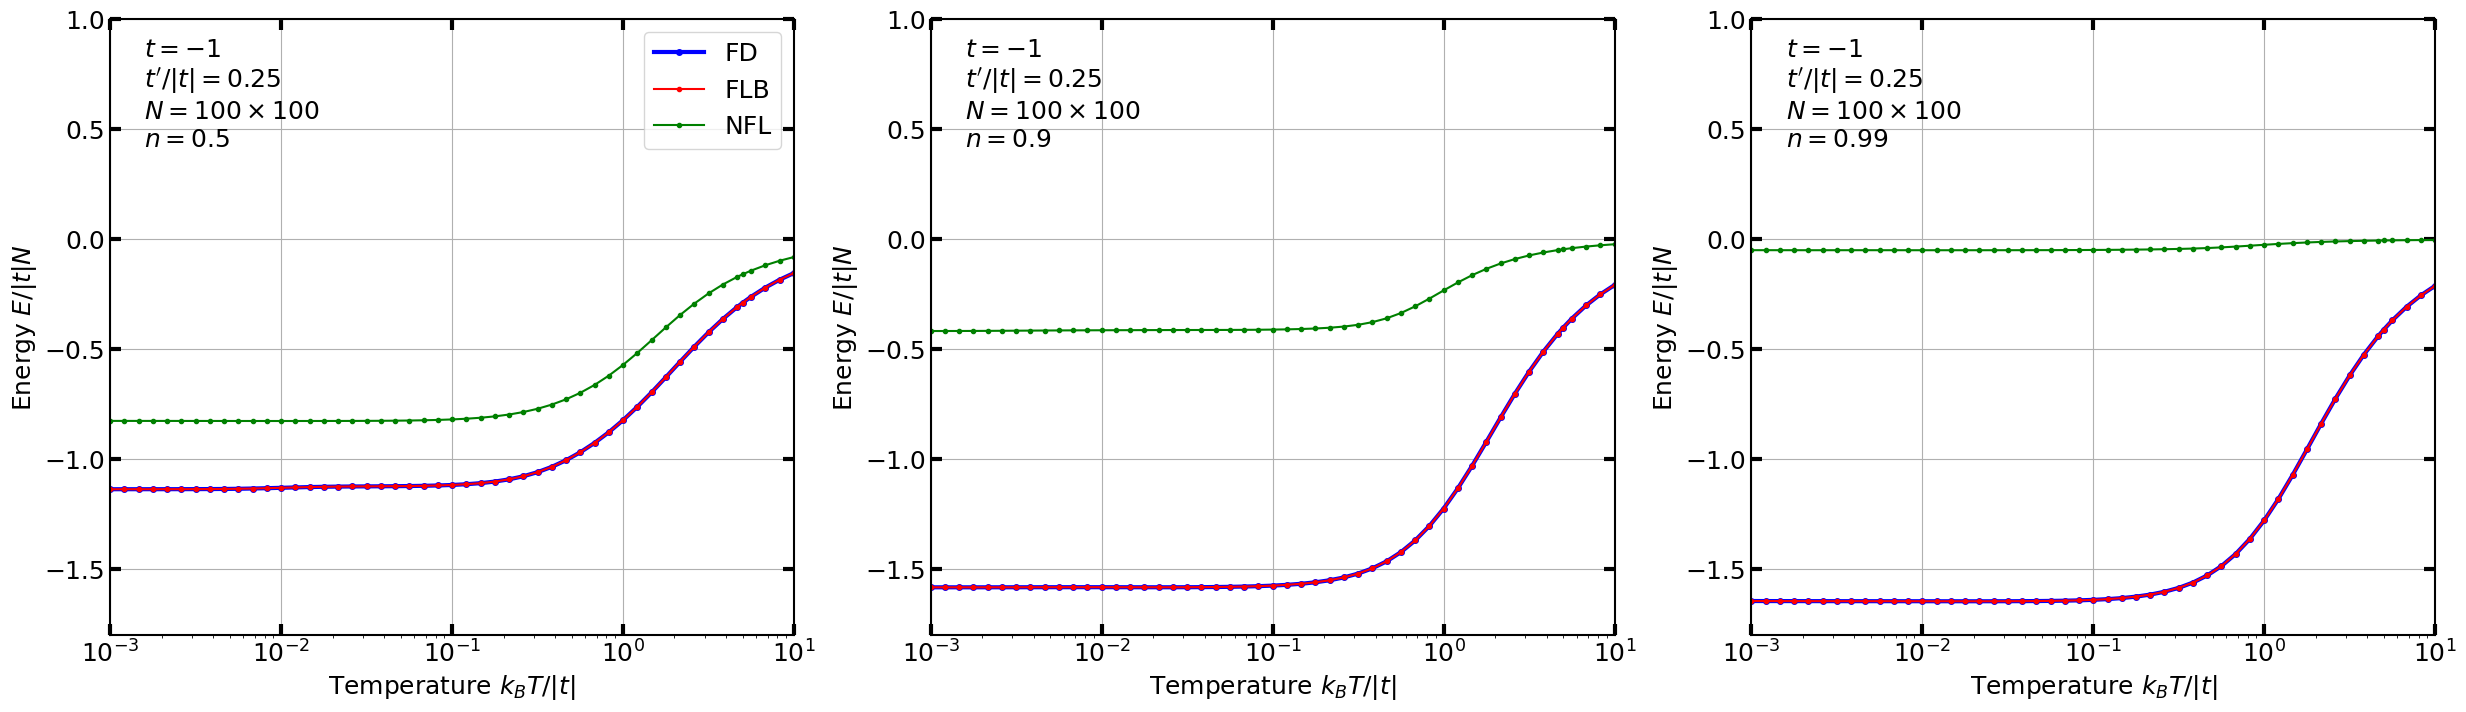

In [33]:
sf.plot_results_temperature(results=energy, n=n_to_plot, betas=betas, distros=distros, cols = 3, t_prim=t_prim,
                        y_label="Energy $E / |t| N$", text_pos=(0.05, 0.97), only_one_legend=True,xlims = (1e-3,10), ylims= (-1.8, 1),
                        fontsize =18, figsize=(10, 8), legend_position="upper right", blue_line=True)

plt.savefig("temp/E_kBT.png", dpi=600, bbox_inches='tight')

# Energia swobodna
$$ \frac{F}{N |t|} =  \frac{1}{N |t|}  \sum_k \epsilon_k n_k - \frac{k_bT}{|t|} \frac{S}{k_bN}$$

In [34]:
for beta in betas:
    for distro in distros:
        fe = - 1/beta * entropy.loc[(distro, beta), :]
        fe += energy.loc[(distro, beta), :]
        freedom_energy.loc[(distro, beta), :] = fe

In [35]:
freedom_energy.T

distributions          FD                                               \
beta            0.0100      0.0121     0.0147     0.0178     0.0215      
0.010           -6.296048   -5.203464  -4.283232  -3.537371   -2.92876   
0.025          -13.439991   -11.10763  -9.143206   -7.55119   -6.25205   
0.050          -23.382567  -19.324793 -15.907297  -13.13752 -10.877353   
0.075          -31.984839  -26.434358 -21.759719 -17.970957 -14.879295   
0.100          -39.705315  -32.815021 -27.012092 -22.308799 -18.470977   
0.125          -46.760987  -38.646423 -31.812177 -26.273302 -21.753541   
0.150          -53.280027  -44.034237  -36.24729 -29.936138 -24.786422   
0.175          -59.346779  -49.048016 -40.374485 -33.345009 -27.608871   
0.200          -65.020701  -53.737604 -44.234803 -36.533176 -30.248754   
0.225          -70.346576  -58.139328 -47.858344 -39.525783 -32.726547   
0.250          -75.359065  -62.281988 -51.268312 -42.342214 -35.058573   
0.275           -80.08514  -66.188037  -54.48373 -44.997874  -37.25747   
0.300          -84.547513  -69.876097  -57.51966 -47.505282 -39.333633   
0.325          -88.764529  -73.361282 -60.388672 -49.874845 -41.295651   
0.350           -92.75184  -76.656711 -63.101327 -52.115271 -43.150765   
0.375          -96.522295  -79.773057  -65.66653 -54.234017 -44.905091   
0.400         -100.087664  -82.719619 -68.092249 -56.237365 -46.563924   
0.425         -103.457476   -85.50482 -70.384931 -58.130937 -48.131837   
0.450          -106.64051  -88.135555 -72.550455 -59.919527 -49.612824   
0.475         -109.644321  -90.618014 -74.594041 -61.607369 -51.010394   
0.500         -112.475341  -92.957934 -76.520216 -63.198255  -52.32765   
0.525         -115.139703  -95.159986 -78.332914 -64.695358 -53.567327   
0.550          -117.64264  -97.228618  -80.03575 -66.101773 -54.731876   
0.575         -119.988668  -99.167553 -81.631932 -67.420086 -55.823505   
0.600         -122.182112  -100.98046  -83.12425 -68.652648 -56.844071   
0.625         -124.226799  -102.67033 -84.515316 -69.801585  -57.79541   
0.650         -126.125899 -104.239934 -85.807393 -70.868705 -58.679053   
0.675         -127.882536 -105.691729 -87.002528 -71.855826 -59.496401   
0.700         -129.499376 -107.028042 -88.102556 -72.764367 -60.248703   
0.725         -130.978836 -108.250778 -89.109093 -73.595701 -60.937076   
0.750          -132.32299 -109.361725 -90.023612 -74.351031 -61.562509   
0.775         -133.533824 -110.362425 -90.847396  -75.03142 -62.125899   
0.800         -134.612923 -111.254316  -91.58158 -75.637806 -62.628011   
0.825         -135.561808 -112.038556 -92.227152 -76.171007 -63.069522   
0.850         -136.381697 -112.716186 -92.784986 -76.631734 -63.451021   
0.875         -137.073688  -113.28812 -93.255784 -77.020587 -63.773007   
0.900         -137.638675 -113.755066 -93.640175 -77.338069 -64.035896   
0.925         -138.077368 -114.117644 -93.938644 -77.584585 -64.240022   
0.950         -138.390326 -114.376301 -94.151569 -77.760448 -64.385646   
0.975         -138.577944 -114.531366 -94.279219  -77.86588 -64.472949   
0.990         -138.630457 -114.574768 -94.314947  -77.89539 -64.497386   

distributions                                                         ...  \
beta           0.0261     0.0316     0.0383     0.0464     0.0562     ...   
0.010          -2.412775  -1.993029  -1.644651   -1.35784  -1.121431  ...   
0.025          -5.150591  -4.254637     -3.511  -2.898849  -2.394269  ...   
0.050          -8.961137  -7.402442  -6.108783  -5.043881  -4.166149  ...   
0.075         -12.258174 -10.126121  -8.356597  -6.900017  -5.699481  ...   
0.100         -15.217228 -12.570758 -10.374082  -8.566031  -7.075809  ...   
0.125         -17.921657 -14.804878 -12.217967 -10.088724  -8.333816  ...   
0.150          -20.42039 -16.869151 -13.921725   -11.4957  -9.496251  ...   
0.175         -22.745789 -18.790181 -15.507271 -12.805114 -10.578088  ...   
0.200         -24.920689 -20.587062 -16.990296 

#### $\frac{F} {k_B N} = f(n)$

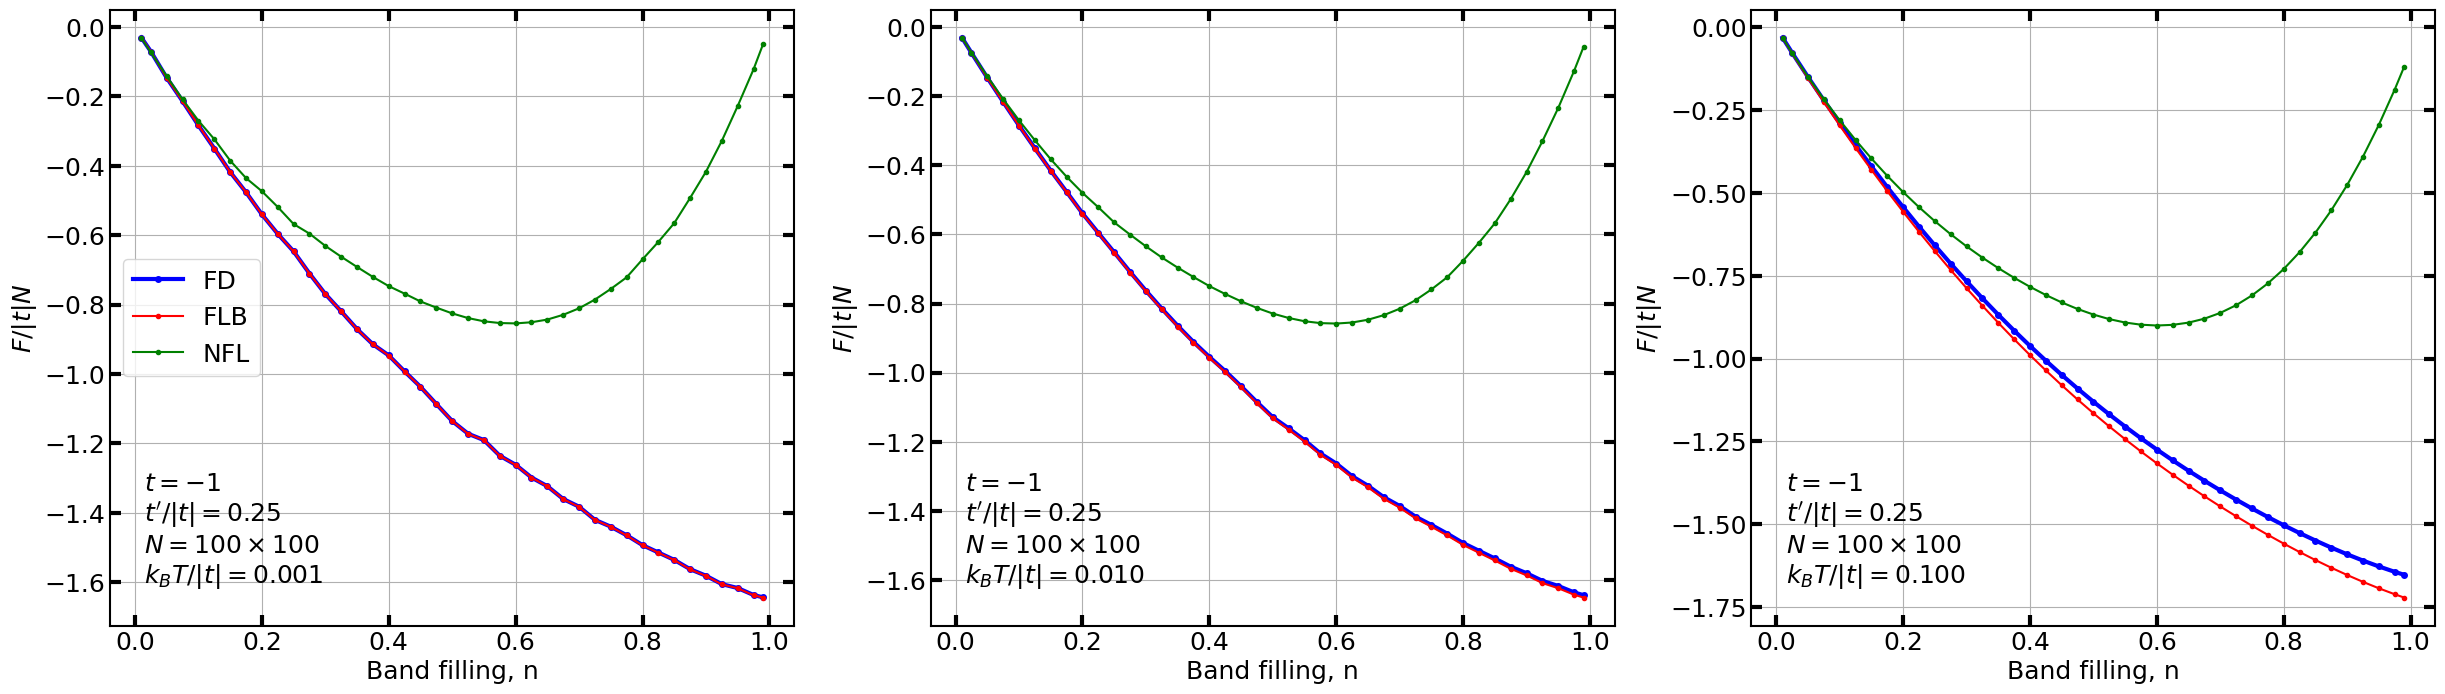

In [36]:
sf.plot_result_n(results=freedom_energy, n=n, betas=betas_to_plot, distros=distros, t_prim=t_prim,
                y_label="$F / |t| N$", cols=3, legend_position="center left", only_one_legend=True,
                text_pos=(0.05, 0.25),  fontsize =18, figsize=(10, 8), blue_line=True)
plt.savefig("temp/F_n.png", dpi=600, bbox_inches='tight')

#### $\frac{F} {k_B N} = f(k_B T/|t|)$


<Figure size 640x480 with 0 Axes>

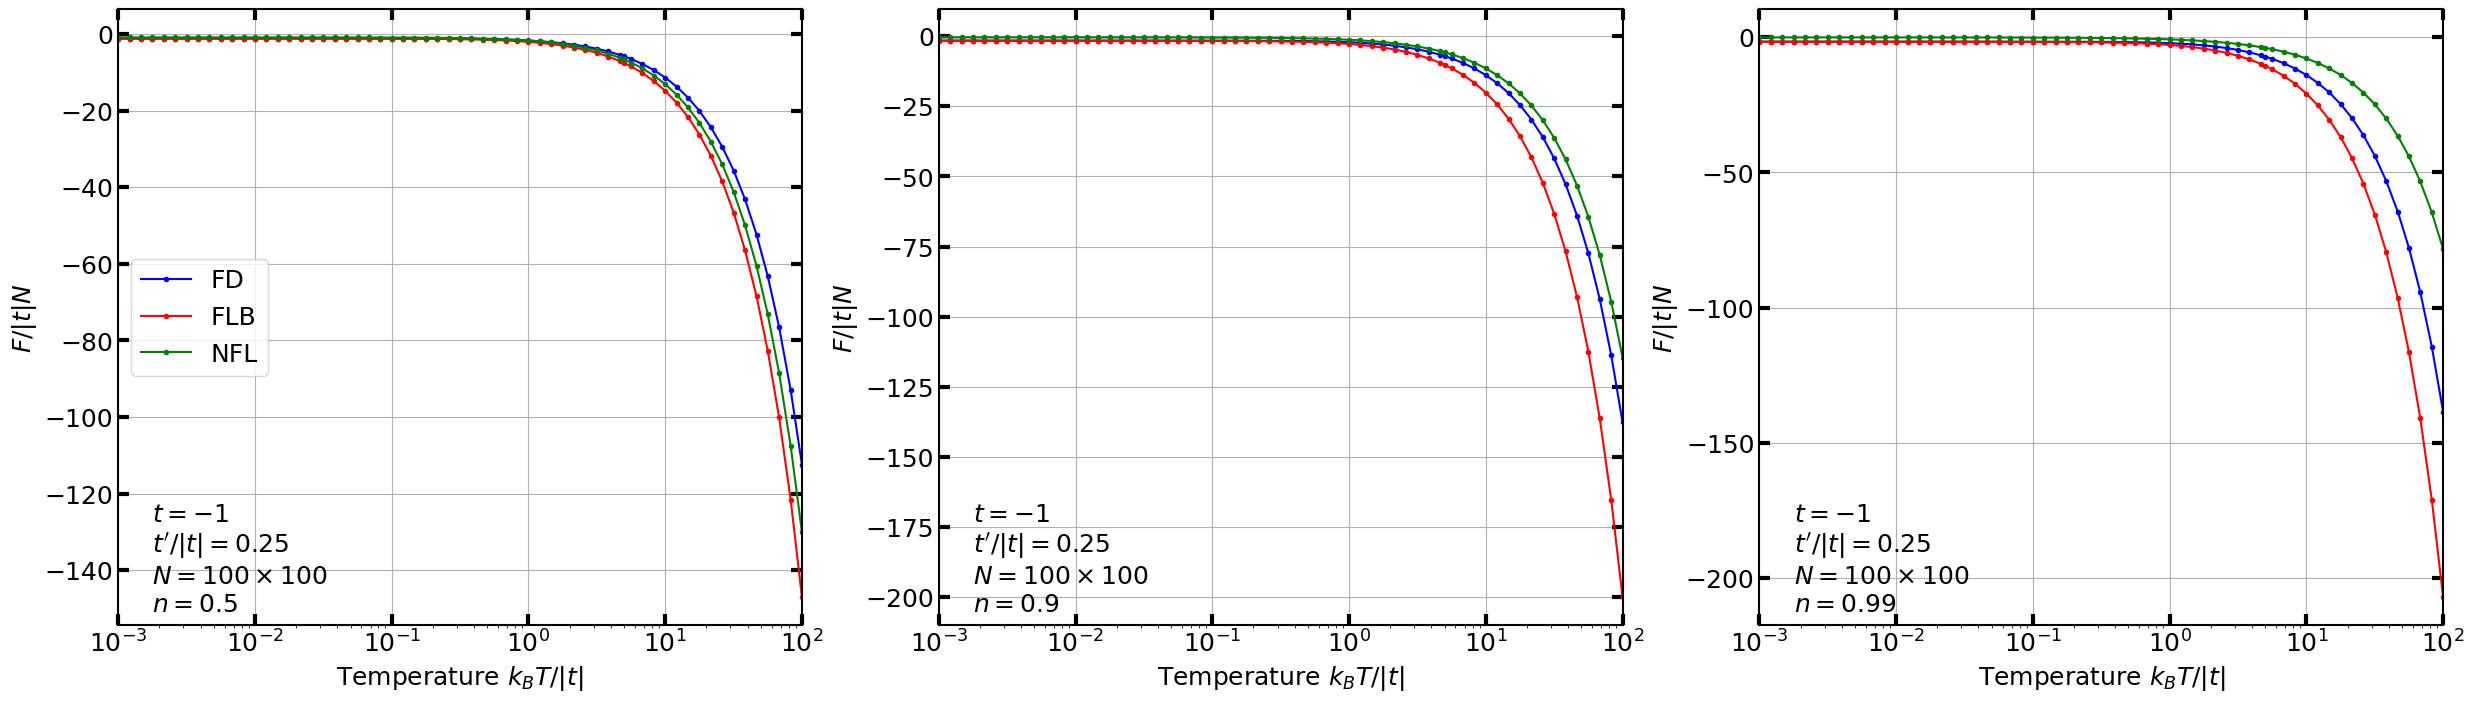

In [37]:
sf.plot_results_temperature(results=freedom_energy, n=n_to_plot, betas=betas, distros=distros, cols = 3, t_prim=t_prim,
                        y_label="$F /|t| N$", legend_position="center left", only_one_legend=True, xlims=(1e-3,100),
                        text_pos=(0.05, 0.2),  fontsize =18, figsize=(10, 8))

plt.savefig("temp/F_kBT.png", dpi=600, bbox_inches='tight')